# Génération de données synthétiques des patients asthmatiques
### Méthode avatar : approche Guillaudeux et al. (2023)

**Groupe 4 : Abdo, Talha, Flora** 

Dans le cadre de nos recherches sur l'asthme, nous sommes confrontés à un défi majeur : comment exploiter les données cliniques des patients tout en garantissant un respect total de leur vie privée ? Aujourd'hui, nous savons que la simple pseudonymisation ne suffit plus. Rocher et al. ont montré que 99,98 % des personnes pouvaient être réidentifiées dans n'importe quel jeu de données pseudonymisé à partir de 15 attributs démographiques.

Pour répondre à cet enjeu, nous appliquons la **méthode Avatar** de Guillaudeux et al. (2023). Cette méthode est patient-centrique : pour chaque vrai patient, elle génère un avatar synthétique en cherchant ses voisins les plus proches dans l'espace des données, puis en tirant aléatoirement un nouveau point dans ce voisinage local.

Chaque avatar est basé sur un patient réel, mais il n'est pas une copie de ce patient. Le patient original n'est pas dans le dataset synthétique.

La qualité des données synthétiques est évaluée par les métriques suivants :
- la **distance de Wasserstein** (ressemblance des distributions),
- les **mesures de corrélation** (conservation des liens entre variables),
- la **distance au plus proche voisin (DCR)** (confidentialité des patients).

**Référence :** Guillaudeux, M. et al. (2023). *Patient-centric synthetic data generation, no reason to risk re-identification in biomedical data analysis.* npj Digital Medicine, 6, 37. https://doi.org/10.1038/s41746-023-00771-5

## 1. Imports

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_selection import VarianceThreshold
from scipy.stats import wasserstein_distance
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

## 2. Chargement des données

In [2]:
data="../../Data/trainDataDC2.csv.gz"
df_reel = pd.read_csv(data, compression='gzip')

print(f'Dimensions : {df_reel.shape[0]} patients × {df_reel.shape[1]} variables')
df_reel.head(4)

Dimensions : 14575 patients × 21 variables


,patid,index_age,previous_asthma_drugs,total_pre_index_cannisters_365,post_index_exacerbations365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,...,rhinitis,adherence,total_pre_index_charge,pre_asthma_days,pre_asthma_charge,pre_asthma_pharma_charge,drug_s,female,log_charges,log_asthma_charge
0,1073754155,14.0,1.0,1.0,0,0.0,0.0,1.0,0.0,1.0,...,0.0,NaN,1224.767473,1.0,314.0,218.13,0.0,NaN,7.110506,5.385091
1,1073799394,NaN,1.0,2.0,2,0.0,1.0,1.0,0.0,0.0,...,1.0,NaN,20290.534269,0.0,NaN,44.98,0.0,0.0,9.917910,3.806218
2,1073854918,62.0,1.0,NaN,0,0.0,0.0,NaN,0.0,0.0,...,0.0,0.738420,2964.254175,NaN,480.0,99.26,0.0,0.0,7.994381,4.597743
3,1073898249,NaN,1.0,2.0,0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.084469,3223.708820,0.0,0.0,59.58,0.0,1.0,8.078288,NaN


In [3]:
df_reel.dtypes

patid                               int64
index_age                         float64
previous_asthma_drugs             float64
total_pre_index_cannisters_365    float64
post_index_exacerbations365         int64
pneumonia                         float64
sinusitis                         float64
acute_bronchitis                  float64
acute_laryngitis                  float64
upper_respiratory_infection       float64
gerd                              float64
rhinitis                          float64
adherence                         float64
total_pre_index_charge            float64
pre_asthma_days                   float64
pre_asthma_charge                 float64
pre_asthma_pharma_charge          float64
drug_s                            float64
female                            float64
log_charges                       float64
log_asthma_charge                 float64
dtype: object

## 3. Prétraitement

Avant d'utiliser la méthode Avatar, nous uniformisons nos données. Nous remplaçons les valeurs manquantes par la médiane (variables numériques) ou la valeur la plus fréquente (binaires). Nous mettons toutes les variables à la même échelle pour qu'aucune n'écrase les autres dans le calcul des distances. Enfin, nous appliquons une transformation logarithmique aux coûts médicaux pour réduire l'impact des valeurs extrêmes.

In [4]:
target = 'post_index_exacerbations365'

# Variables numériques 
num_features = [
    'index_age', 'previous_asthma_drugs',
    'total_pre_index_cannisters_365', 
    'pre_asthma_days', 
    'adherence'
]

# Variables financières (très asymétriques → transformation log)
skewed_features = [
    'total_pre_index_charge', 
    'pre_asthma_charge', 
    'pre_asthma_pharma_charge'
]

# Variables binaires 
binary_features = [
    'pneumonia', 
    'sinusitis', 
    'acute_bronchitis', 'acute_laryngitis',
    'upper_respiratory_infection', 
    'gerd', 
    'rhinitis', 
    'drug_s', 
    'female'
]

all_features = num_features + skewed_features + binary_features

# Séparation features et cible
X_df = df_reel[all_features].copy()
y = df_reel[target].copy()

print(f'Features : {len(all_features)} variables')
print(f'Patients : {len(X_df)}')

Features : 17 variables
Patients : 14575


In [5]:
# Pipeline pour les variables numériques
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline pour les variables asymétriques (log1p réduit l'asymétrie)
skewed_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler',  StandardScaler())
])

# Pipeline pour les variables binaires
binary_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
])


# Assemblage des 3 pipelines
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('skewed', skewed_pipeline, skewed_features),
    ('binary', binary_pipeline, binary_features)
])

X = preprocessor.fit_transform(X_df)
feature_names = preprocessor.get_feature_names_out()

# Supprimer les colonnes à variance nulle (inutiles pour la PCA)
selector = VarianceThreshold(threshold=0.0)
X = selector.fit_transform(X)
feature_names = feature_names[selector.get_support()]

print(f'Données prétraitées : {X.shape}')
print(f'Valeurs manquantes restantes : {np.isnan(X).sum()}')

Données prétraitées : (14575, 16)
Valeurs manquantes restantes : 0


In [6]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('skewed', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [7]:
X

array([[-1.70420068,  0.26807466, -0.16443691, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.16632608,  1.71948184, -0.59089028, ...,  1.        ,
         0.        ,  0.        ],
       [ 1.62118024,  0.26807466, -0.16443691, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [-0.3186253 ,  0.26807466, -0.59089028, ...,  0.        ,
         1.        ,  1.        ],
       [ 0.16632608,  1.71948184,  0.26201646, ...,  1.        ,
         1.        ,  1.        ],
       [ 0.16632608,  0.26807466,  1.11492321, ...,  1.        ,
         1.        ,  1.        ]], shape=(14575, 16))

## 4. Exploration des données réelles

On visualise les distributions qui serviront de **référence** pour évaluer la qualité des données synthétiques.

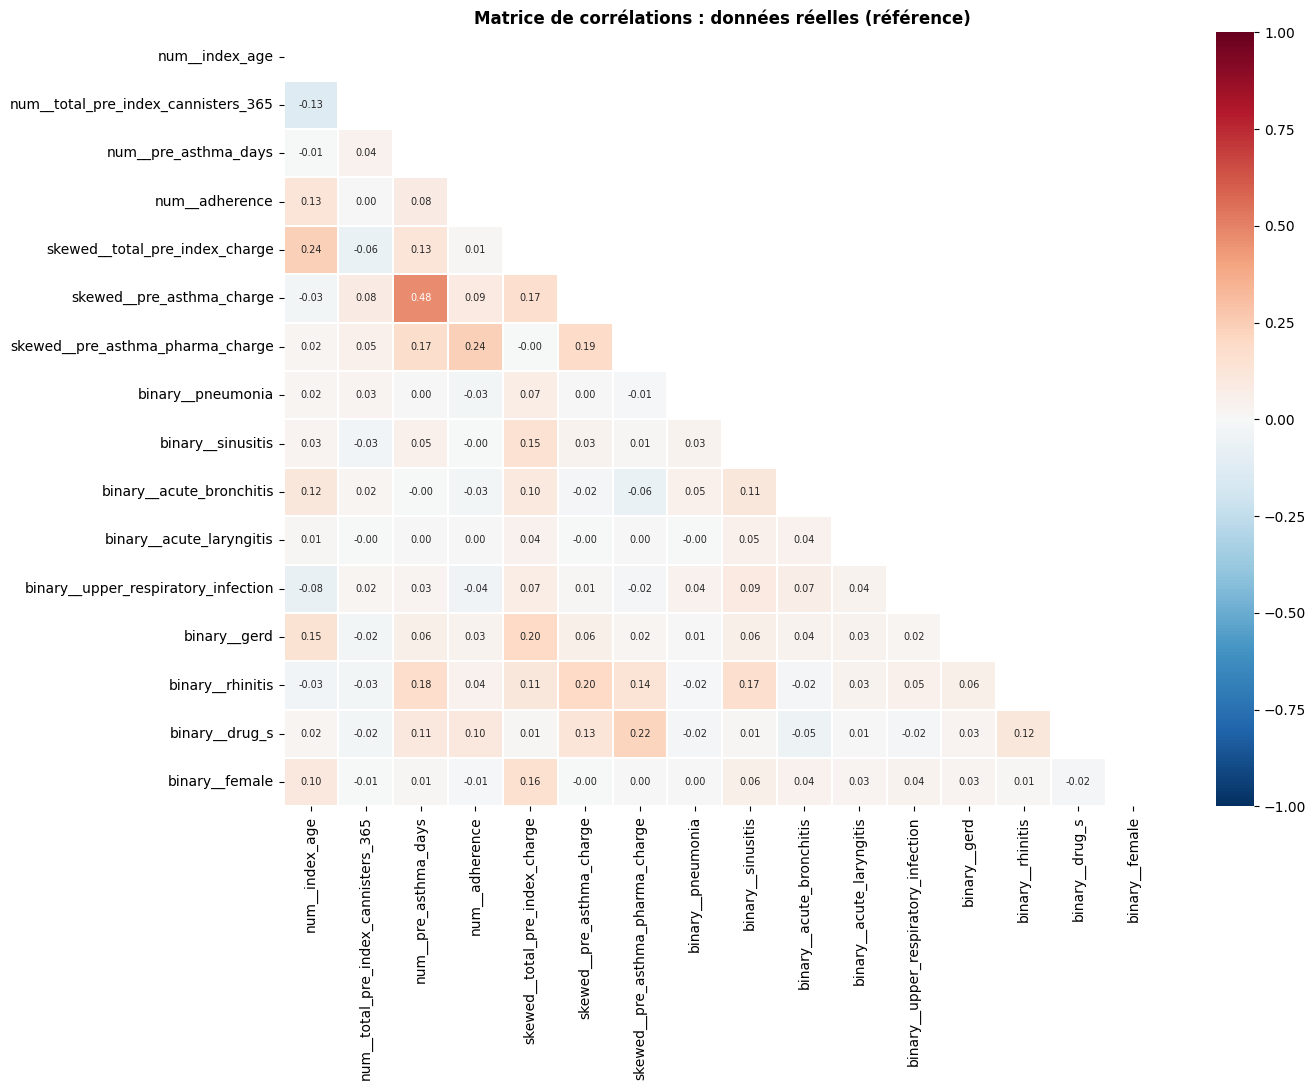

In [8]:
# Matrice de corrélation de référence
real_df = pd.DataFrame(X, columns=feature_names)

corr_real = real_df.corr()
mask = np.triu(np.ones_like(corr_real, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr_real, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot_kws={'size': 7}, ax=ax, linewidths=0.3)
ax.set_title('Matrice de corrélations : données réelles (référence)', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Méthode Avatar selon Guillaudeux et al

**Étape 1 : Projection PCA**
Dans un premier temps, toutes les variables des patients sont projetées dans un espace réduit grâce à l'analyse en composantes principales (PCA). Cette réduction conserve l'essentiel de l'information tout en éliminant le bruit statistique, rendant les distances entre patients plus significatives.

**Étape 2 : Voisinage local (KNN)**
Pour chaque patient, nous identifions ses k plus proches voisins dans cet espace réduit (algorithme KNN). Ces voisins définissent une zone locale regroupant les individus qui lui ressemblent le plus sur le plan clinique..

**Étape 3 : Génération de l'avatar**
Un avatar est généré en calculant une combinaison pondérée des k voisins avec des poids aléatoires (formule Di × Ri × Ci). Ce caractère stochastique garantit que l'avatar ne correspond à aucun patient réel, assurant la confidentialité.

**Étape 4 : Projection inverse**
Les avatars sont retransformés dans l'espace original via l'inverse de la PCA. Nous obtenons ainsi des données synthétiques exprimées avec les mêmes unités et variables que nos données réelles.

**Formule des poids :**
- **Di** = 1/distance : voisins proches ont plus d'influence
- **Ri** ~ Exp(1) : variabilité aléatoire
- **Ci** = (1/2)^permutation : pondération décroissante aléatoire
- **Wi** = Di × Ri × Ci / sum(...) : poids normalisés

In [9]:
def generer_avatars(X, k=20, n_components=10, random_state=42):
    """
    Génération des données synthétiques par la méthode Avatar.
    Selon la méthode de Guillaudeux et al. (2023).

    Paramètres :
      X : array numpy prétraité (patients × variables)
      k : nombre de voisins
      n_components : dimensions de projection (PCA)
      random_state : assure la reproductibilité des résultats
    Retourne :
      X_synth : array numpy de même taille que X
    """
    np.random.seed(random_state)
    n = X.shape[0]

    # Étape 1 : Projection PCA
    pca = PCA(n_components=n_components)
    X_proj = pca.fit_transform(X)

    # Étape 2 : KNN 
    knn = NearestNeighbors(n_neighbors=k + 1, metric='euclidean')
    knn.fit(X_proj)
    distances, indices = knn.kneighbors(X_proj)

    # Étape 3 : Génération des avatars
    avatars = np.zeros_like(X_proj)

    for i in range(n):
        neigh_idx = indices[i][1:] # exclure soi-même
        neigh_dist = distances[i][1:]

        Di = 1.0 / (neigh_dist + 1e-8) # poids par proximité
        Ri = np.random.exponential(scale=1.0, size=k)  # variabilité aléatoire
        perm = np.random.permutation(np.arange(1, k + 1))
        Ci = (1/2) ** perm # pondération décroissante

        Pi = Di * Ri * Ci
        Wi = Pi / (Pi.sum() + 1e-12) # normalisation

        avatars[i] = np.sum(Wi[:, None] * X_proj[neigh_idx], axis=0)

    # Étape 4 : Projection inverse
    X_synth = pca.inverse_transform(avatars)

    return X_synth

In [10]:
# Génération du dataset synthétique (paramètres par défaut)
X_synth = generer_avatars(X, k=20, n_components=10)
df_synth = pd.DataFrame(X_synth, columns=feature_names)
df_synth.head(4)

,num__index_age,num__total_pre_index_cannisters_365,num__pre_asthma_days,num__adherence,skewed__total_pre_index_charge,skewed__pre_asthma_charge,skewed__pre_asthma_pharma_charge,binary__pneumonia,binary__sinusitis,binary__acute_bronchitis,binary__acute_laryngitis,binary__upper_respiratory_infection,binary__gerd,binary__rhinitis,binary__drug_s,binary__female
0,-1.713568,0.278081,-0.153614,-0.615288,-0.988823,0.370207,1.015570,0.054101,0.437767,0.568389,0.015753,0.419930,-0.029754,-0.159290,0.105149,0.994815
1,0.145301,1.726089,-0.159157,-0.509415,1.141615,0.477691,-0.050797,0.080930,0.600685,0.344833,0.026054,0.305877,0.176545,0.781615,0.156829,0.568423
2,0.997389,0.267355,0.212945,2.090829,0.191897,0.674667,-0.005659,0.036083,-0.103450,0.127767,0.004862,-0.004650,0.138210,0.042445,0.190952,0.245969
3,-0.348990,1.718821,-0.590969,-0.658082,0.310891,-1.376496,-0.264256,0.092966,0.713407,0.765879,0.029123,0.473463,0.083636,-0.000195,-0.032441,0.981980


In [11]:
df_synth.shape

(14575, 16)

In [12]:
df_synth.describe()

,num__index_age,num__total_pre_index_cannisters_365,num__pre_asthma_days,num__adherence,skewed__total_pre_index_charge,skewed__pre_asthma_charge,skewed__pre_asthma_pharma_charge,binary__pneumonia,binary__sinusitis,binary__acute_bronchitis,binary__acute_laryngitis,binary__upper_respiratory_infection,binary__gerd,binary__rhinitis,binary__drug_s,binary__female
count,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000,14575.000000
mean,-0.000567,-0.003394,-0.040648,-0.057858,-0.015679,-0.021950,-0.021386,0.044344,0.251167,0.213580,0.014677,0.189678,0.089222,0.344305,0.143470,0.696864
std,0.919418,0.986293,0.865655,0.917894,0.874413,0.960482,0.909395,0.020676,0.298218,0.241118,0.008800,0.123996,0.066572,0.399031,0.104223,0.423918
min,-1.861164,-1.201335,-0.603248,-0.926546,-4.806618,-1.392556,-2.238840,-0.056607,-0.131896,-0.276914,-0.010616,-0.097152,-0.248367,-0.246610,-0.134205,-0.053366
25%,-0.592875,-1.180266,-0.565472,-0.633699,-0.395461,-1.373589,-0.635913,0.030913,-0.016630,0.055574,0.008308,0.090917,0.048405,0.031796,0.063528,0.169992
50%,0.180450,0.266431,-0.157068,-0.421486,0.032672,0.399775,-0.234377,0.043646,0.179644,0.156915,0.013771,0.171281,0.096290,0.133114,0.130379,0.982560
75%,0.661851,0.272908,0.107899,-0.002430,0.460754,0.658749,0.590612,0.058137,0.458369,0.370691,0.020567,0.273238,0.135294,0.778172,0.213014,1.001458
max,1.760175,1.736578,20.930375,3.391046,2.772435,2.007371,2.648627,0.126627,1.298092,1.074177,0.044963,0.668299,0.284444,1.229245,0.470444,1.056314


In [13]:
df_reel.describe()

,patid,index_age,previous_asthma_drugs,total_pre_index_cannisters_365,post_index_exacerbations365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,...,rhinitis,adherence,total_pre_index_charge,pre_asthma_days,pre_asthma_charge,pre_asthma_pharma_charge,drug_s,female,log_charges,log_asthma_charge
count,1.457500e+04,13085.000000,13144.0,13131.000000,14575.000000,13072.000000,13084.000000,13127.000000,13166.000000,13114.000000,...,13109.000000,12712.000000,13109.000000,13124.000000,13103.000000,13158.000000,13190.000000,13166.000000,13146.000000,13185.000000
mean,1.317034e+09,38.325793,1.0,0.794989,0.175163,0.050719,0.319703,0.262284,0.017089,0.223730,...,0.404989,0.253408,8473.137523,1.428223,553.973155,242.883670,0.162851,0.633298,7.982269,4.204495
std,1.546356e+08,15.210683,0.0,0.723036,0.638298,0.219432,0.466379,0.439893,0.129610,0.416759,...,0.490909,0.230140,21989.077382,2.467550,2024.886360,444.098457,0.369243,0.481923,1.645137,1.705917
min,1.073754e+09,12.000000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.005450,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.183442e+09,26.000000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.084469,1237.050948,0.000000,0.000000,21.410000,0.000000,0.000000,7.113415,3.063858
50%,1.282389e+09,41.000000,1.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.168937,3171.706218,1.000000,131.000000,46.160000,0.000000,1.000000,8.047814,3.849722
75%,1.493697e+09,51.000000,1.0,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,...,1.000000,0.337875,8091.168039,2.000000,415.750000,227.737500,0.000000,1.000000,9.004598,5.438340
max,1.771899e+09,65.000000,1.0,2.000000,13.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,875872.580590,71.000000,79280.910000,5463.140000,1.000000,1.000000,13.682976,8.605779


---
## 6. Metrics d évaluation 

| Métrique | Ce qu'elle mesure | Idéal |
|---|---|---|
| **Wasserstein** | Ressemblance des distributions | proche de 0 |
| **Corrélation** | Conservation des liens entre variables | proche de 0 |
| **DCR** | Confidentialité (distance au plus proche voisin) | score élevé |



In [14]:
# Métrique 1 : Wasserstein
def calc_wasserstein(real_df, synth_df):
    scores = {}
    for col in real_df.columns:
        r = real_df[col].values
        s = synth_df[col].values
        if r.std() < 1e-6: # pour éviter constantes
            continue
        scores[col] = wasserstein_distance(r, s)
    return scores, float(np.mean(list(scores.values())))

In [15]:
# Métrique 2 : Différence de corrélation
def calc_corr_diff(real_df, synth_df):
    R = real_df.values
    S = synth_df.values
    mask = (R.std(axis=0) > 1e-6) & (S.std(axis=0) > 1e-6)
    corr_r = np.corrcoef(R[:, mask], rowvar=False)
    corr_s = np.corrcoef(S[:, mask], rowvar=False)
    return float(np.abs(corr_r - corr_s).mean())

In [16]:
# Métrique 3 : DCR
def calc_dcr(real_df, synth_df):
    distances = pairwise_distances(synth_df.values, real_df.values)
    return float(distances.min(axis=1).mean())

In [17]:
# Évaluation  
def evaluer(real_df, synth_df):
    _, w = calc_wasserstein(real_df, synth_df)
    corr = calc_corr_diff(real_df, synth_df)
    dcr = calc_dcr(real_df, synth_df)
    return {'wasserstein': round(w, 4), 
            'corr_diff': round(corr, 4), 
            'dcr': round(dcr, 4)
           }

In [18]:
# Calcul des métriques initiales
resultats = evaluer(real_df, df_synth)
resultats

{'wasserstein': 0.1181, 'corr_diff': 0.1574, 'dcr': 0.661}

Nous pouvons supposer à partir de ces résultats que : 
- la distribution des varaibles sont assez correctes (Wasserstein = 0.1181)
- une bonne conservation des liens entre variables (corr_diff = 0.1574)
- la confidentialité est satisfaisante avec un DCR de 0.661 : les avatars générés sont suffisamment éloignés des patients réels pour limiter le risque de ré-identification.

## 7. Optimisation des paramètres (GridSearch) 

On teste plusieurs combinaisons de k (nombre de voisins) et n_components (dimensions PCA) pour trouver le meilleur équilibre.

**Selon l'article :**
- **k augmente** : meilleure confidentialité (DCR augmente) mais distributions moins fidèles (Wasserstein augmente)
- **n_components augmente** : meilleure fidélité statistique mais confidentialité réduite

In [19]:
# Grille de recherche
param_grid = {
    'k'           : [5, 10, 15, 20],
    'n_components': [8, 10, 15]
}

grid_results = []

for k, n_comp in itertools.product(param_grid['k'], param_grid['n_components']):

    X_s = generer_avatars(X, k=k, n_components=n_comp)
    synth = pd.DataFrame(X_s, columns=feature_names)
    res = evaluer(real_df, synth)

    grid_results.append({'k': k, 'n_components': n_comp, **res})

    print(f'  k={k:2d}, n_comp={n_comp:2d} → W={res["wasserstein"]:.4f}  '
          f'C={res["corr_diff"]:.4f}  DCR={res["dcr"]:.4f}')

df_grid = pd.DataFrame(grid_results)

  k= 5, n_comp= 8 → W=0.1348  C=0.2259  DCR=0.7757
  k= 5, n_comp=10 → W=0.1051  C=0.1523  DCR=0.6242
  k= 5, n_comp=15 → W=0.0544  C=0.0388  DCR=0.4039
  k=10, n_comp= 8 → W=0.1398  C=0.2268  DCR=0.7853
  k=10, n_comp=10 → W=0.1114  C=0.1539  DCR=0.6452
  k=10, n_comp=15 → W=0.0643  C=0.0407  DCR=0.4507
  k=15, n_comp= 8 → W=0.1431  C=0.2283  DCR=0.7870
  k=15, n_comp=10 → W=0.1150  C=0.1560  DCR=0.6533


KeyboardInterrupt: 

In [ ]:
# Sélection des meilleurs paramètres
# Score : on minimise wasserstein et corr_diff, on maximise dcr
df_grid['score'] = -df_grid['wasserstein'] - df_grid['corr_diff'] + df_grid['dcr']
best_row = df_grid.sort_values('score', ascending=False).iloc[0]

print('Tableau des résultats (trié par DCR) :')
print(df_grid.sort_values('dcr').to_string(index=False))
print()

Tableau des résultats (trié par DCR) :
 k  n_components  wasserstein  corr_diff    dcr  score
 5            15       0.0544     0.0388 0.4039 0.3107
10            15       0.0643     0.0407 0.4507 0.3457
15            15       0.0699     0.0438 0.4750 0.3613
20            15       0.0742     0.0458 0.4927 0.3727
 5            10       0.1051     0.1523 0.6242 0.3668
10            10       0.1114     0.1539 0.6452 0.3799
15            10       0.1150     0.1560 0.6533 0.3823
20            10       0.1181     0.1574 0.6610 0.3855
 5             8       0.1348     0.2259 0.7757 0.4150
10             8       0.1398     0.2268 0.7853 0.4187
15             8       0.1431     0.2283 0.7870 0.4156
20             8       0.1456     0.2300 0.7908 0.4152



In [ ]:
print(f'Meilleurs paramètres : k={int(best_row.k)}, n_components={int(best_row.n_components)}')
print(f'Wasserstein : {best_row.wasserstein:.4f}')
print(f'Corr diff : {best_row.corr_diff:.4f}')
print(f'DCR : {best_row.dcr:.4f}')

Meilleurs paramètres : k=10, n_components=8
Wasserstein : 0.1398
Corr diff : 0.2268
DCR : 0.7853


Les résultats de la grille de recherche confirme le compromis observé dans l'article entre la fidélité et la confidentialité.

Le paramètre n_components est le facteur le plus influent : passer de 8 à 15 composantes réduit le Wasserstein (de ~0.14 à ~0.05) et la différence de corrélation (de ~0.23 à ~0.04) mais divise également le DCR par deux (de ~0.79 à ~0.45). 

Le paramètre k a quant à lui un effet plus modéré : son augmentation de 5 à 20 dégrade légèrement la fidélité tout en améliorant la confidentialité.

En effet, selon l'article : 
- si k petit : k = 5
    - mélange de 5 patients très proches
    - très réaliste
    - risque de confidentialité 
    - avatar moins diversifié 

- si k grand : k=50
    - mélange large
    - plus flou
    - securisé 
    - avatar plus diversifié

**k influence la confidentialité et qualité**

## 8. Génération finale avec les meilleurs paramètres

In [ ]:
K_BEST = int(best_row.k)
NCOMP_BEST = int(best_row.n_components)

print(f'Génération finale : k={K_BEST}, n_components={NCOMP_BEST}...')
X_final = generer_avatars(X, k=K_BEST, n_components=NCOMP_BEST)
df_final = pd.DataFrame(X_final, columns=feature_names)

Génération finale : k=10, n_components=8...


In [ ]:
res_final = evaluer(real_df, df_final)
res_final

{'wasserstein': 0.1398, 'corr_diff': 0.2268, 'dcr': 0.7853}

Après optimisation des paramètres, la configuration retenue est **k=10, n_components=8**. Malgré une légère augmentation des métriques de  wasserstein (0.1181 -> 0.1398) et de la corrélation (0.1574 -> 0.2268), on obtient une augmentation du DCR (0.661 -> 0.7853). Cela garantit qu'aucun avatar ne ressemble trop à un vrai patient et renforçant ainsi la protection contre le risque de ré-identification.

## 9. Statistique descriptive et distribution

In [ ]:
# Comparaison des statistiques descriptives
rows = []
for col in real_df.columns:
    r_mean = real_df[col].mean()
    s_mean = df_final[col].mean()
    r_std = real_df[col].std()
    s_std = df_final[col].std()
    rows.append({
        'variable' : col.replace('num__','').replace('skewed__','').replace('binary__',''),
        'moy_reel' : round(r_mean, 4),
        'moy_synth' : round(s_mean, 4),
        'diff_moy' : round(abs(s_mean - r_mean), 4),
        'std_reel' : round(r_std, 4),
        'std_synth' : round(s_std, 4),
        'diff_std' : round(abs(s_std - r_std), 4),
    })

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

                      variable  moy_reel  moy_synth  diff_moy  std_reel  std_synth  diff_std
                     index_age    0.0000    -0.0029    0.0029    1.0000     0.9475    0.0526
total_pre_index_cannisters_365    0.0000    -0.0013    0.0013    1.0000     0.9945    0.0055
               pre_asthma_days   -0.0000    -0.0317    0.0317    1.0000     0.9090    0.0911
                     adherence    0.0000    -0.0443    0.0443    1.0000     0.9509    0.0491
        total_pre_index_charge   -0.0000    -0.0104    0.0104    1.0000     0.9123    0.0877
             pre_asthma_charge   -0.0000    -0.0189    0.0189    1.0000     0.9687    0.0313
      pre_asthma_pharma_charge   -0.0000    -0.0113    0.0113    1.0000     0.9397    0.0603
                     pneumonia    0.0455     0.0456    0.0001    0.2084     0.0177    0.1907
                     sinusitis    0.2870     0.2759    0.0111    0.4524     0.2797    0.1727
              acute_bronchitis    0.2362     0.2337    0.0025    0.424

In [ ]:
print(f"Différence moyenne des moyennes : {comparison['diff_moy'].mean():.4f}")
print(f"Différence moyenne des std : {comparison['diff_std'].mean():.4f}")

Différence moyenne des moyennes : 0.0100
Différence moyenne des std : 0.1535


Les statistiques descriptives montrent que les moyennes des variables sont très proches entre les données réelles et synthétiques, ce qui indique une bonne reproduction des distributions. L'écart-type présente une différence modérée, suggérant une légère perte de variabilité dans les données synthétiques, ce qui est attendu avec la méthode Avatar.

#####  Analyse de confidentialité

Correspondances exactes : 0
Distance minimale moyenne : 0.7853
Distance minimale min     : 0.3490


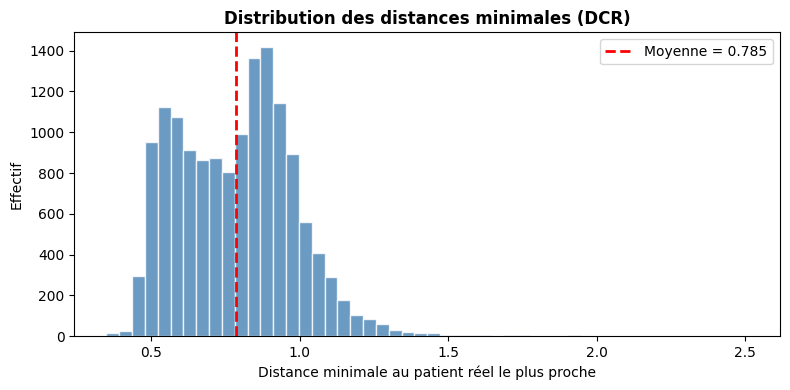

In [ ]:
# Vérification : aucun avatar ne doit être identique à un vrai patient
real_set  = set(map(tuple, real_df.values.round(6)))
synth_set = set(map(tuple, df_final.values.round(6)))
n_matches = len(real_set.intersection(synth_set))

print('Correspondances exactes :', n_matches)

# Distribution des distances minimales
dist     = pairwise_distances(df_final.values, real_df.values)
min_dist = dist.min(axis=1)

print(f'Distance minimale moyenne : {np.mean(min_dist):.4f}')
print(f'Distance minimale min     : {np.min(min_dist):.4f}')

plt.figure(figsize=(8, 4))
plt.hist(min_dist, bins=50, color='steelblue', alpha=0.8, edgecolor='white')
plt.axvline(np.mean(min_dist), color='red', ls='--', lw=2,
            label=f'Moyenne = {np.mean(min_dist):.3f}')
plt.xlabel('Distance minimale au patient réel le plus proche')
plt.ylabel('Effectif')
plt.title('Distribution des distances minimales (DCR)', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

Aucun avatar généré n'est identique à un patient réel, ce qui confirme l'absence de duplication. La distance minimale moyenne de 0.79 indique que les avatars sont globalement bien éloignés des patients réels, tandis que la distance minimale de 0.35 montre que même l'avatar le plus proche d'un vrai patient reste à une distance suffisante pour limiter tout risque de ré-identification.

## 10. Visualisations et comparaison 

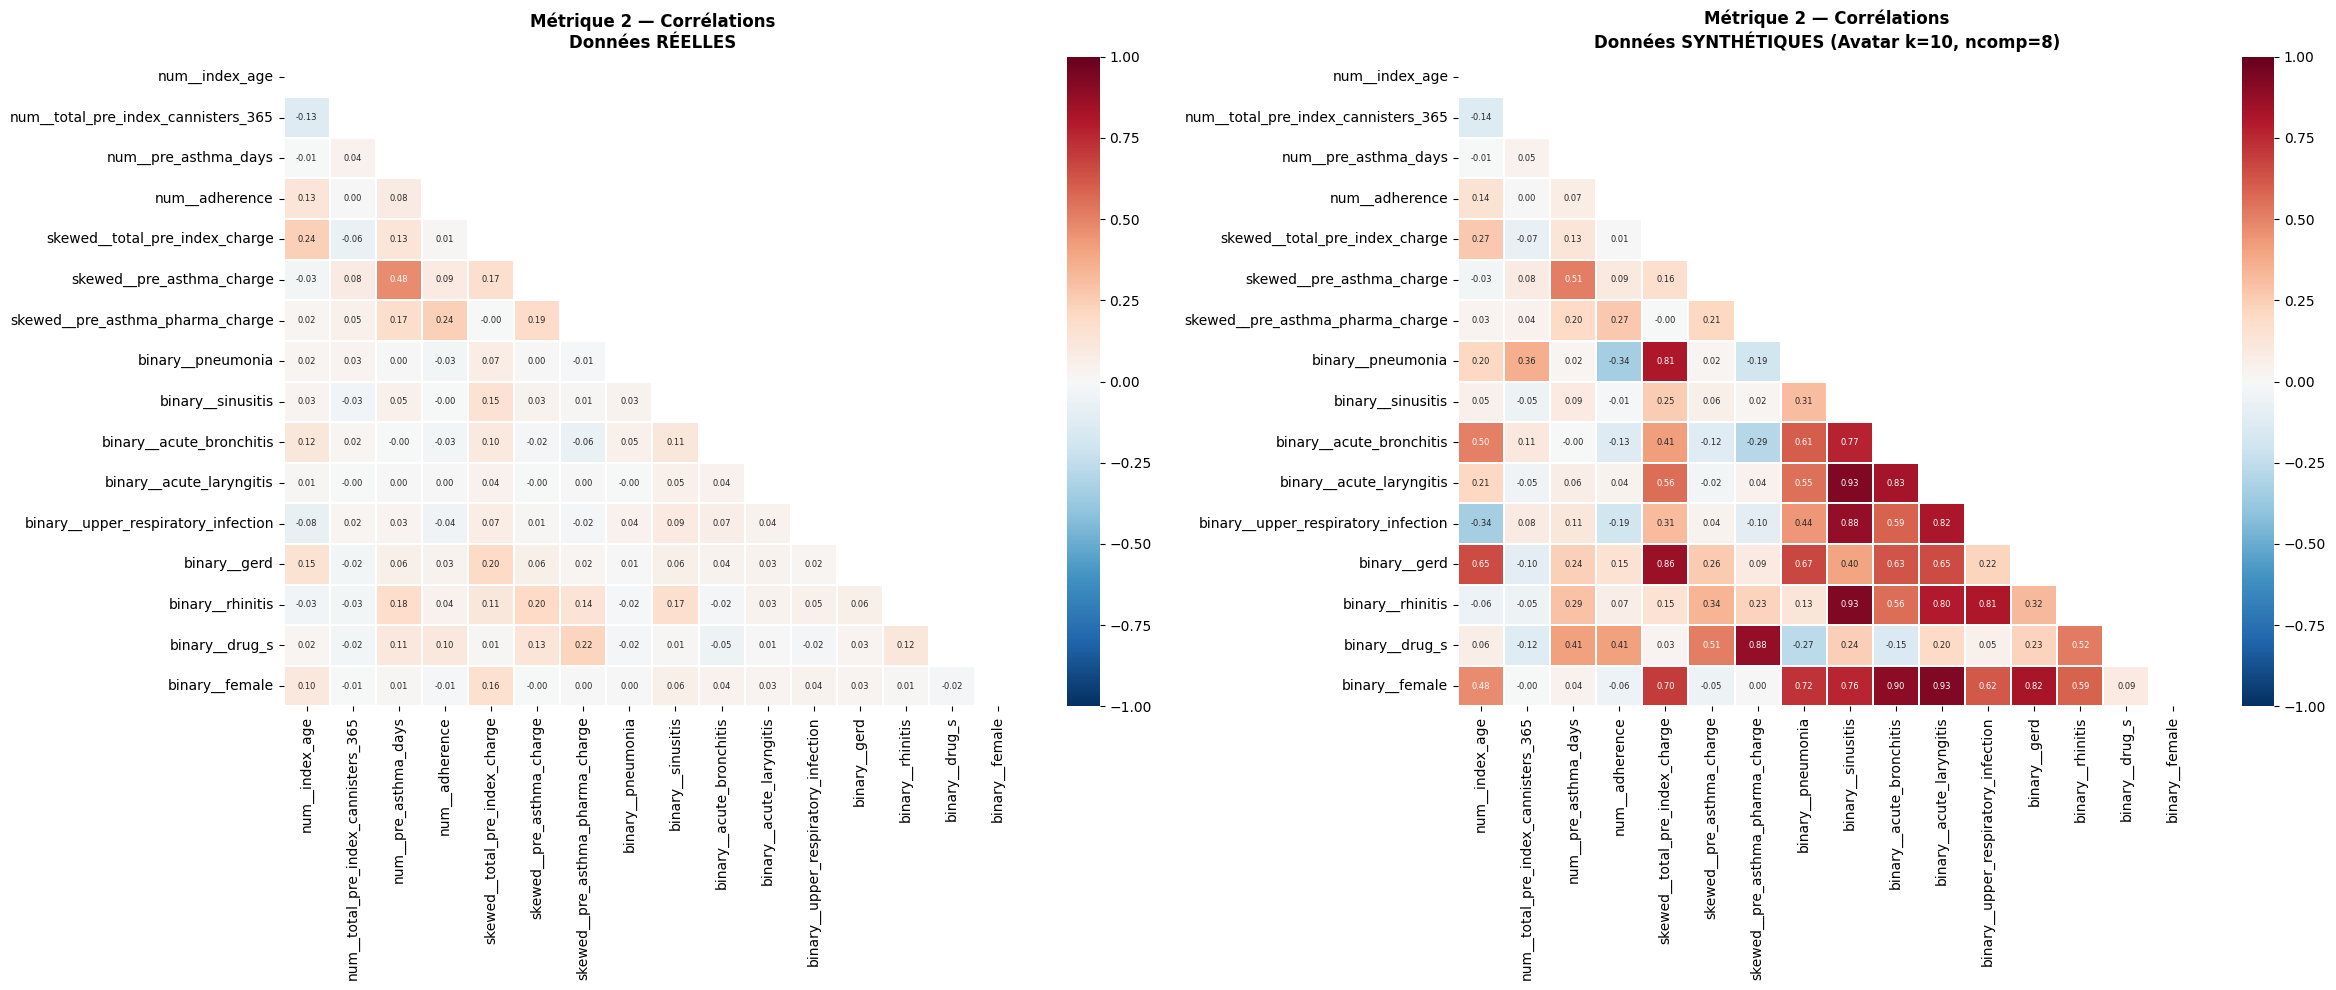

Différence moyenne des corrélations : 0.2268


In [ ]:
# Comparaison des matrices de corrélation

fig, axes = plt.subplots(1, 2, figsize=(24, 10))

for ax, df_plot, titre in zip(
    axes,
    [real_df, df_final],
    ['Données RÉELLES', f'Données SYNTHÉTIQUES (Avatar k={K_BEST}, ncomp={NCOMP_BEST})']
):
    corr = df_plot.corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
                cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                annot_kws={'size': 6}, ax=ax, linewidths=0.3)
    ax.set_title(f'Métrique 2 — Corrélations\n{titre}', fontweight='bold')

plt.tight_layout()
plt.savefig('fig_05_correlations.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Différence moyenne des corrélations : {res_final["corr_diff"]:.4f}')

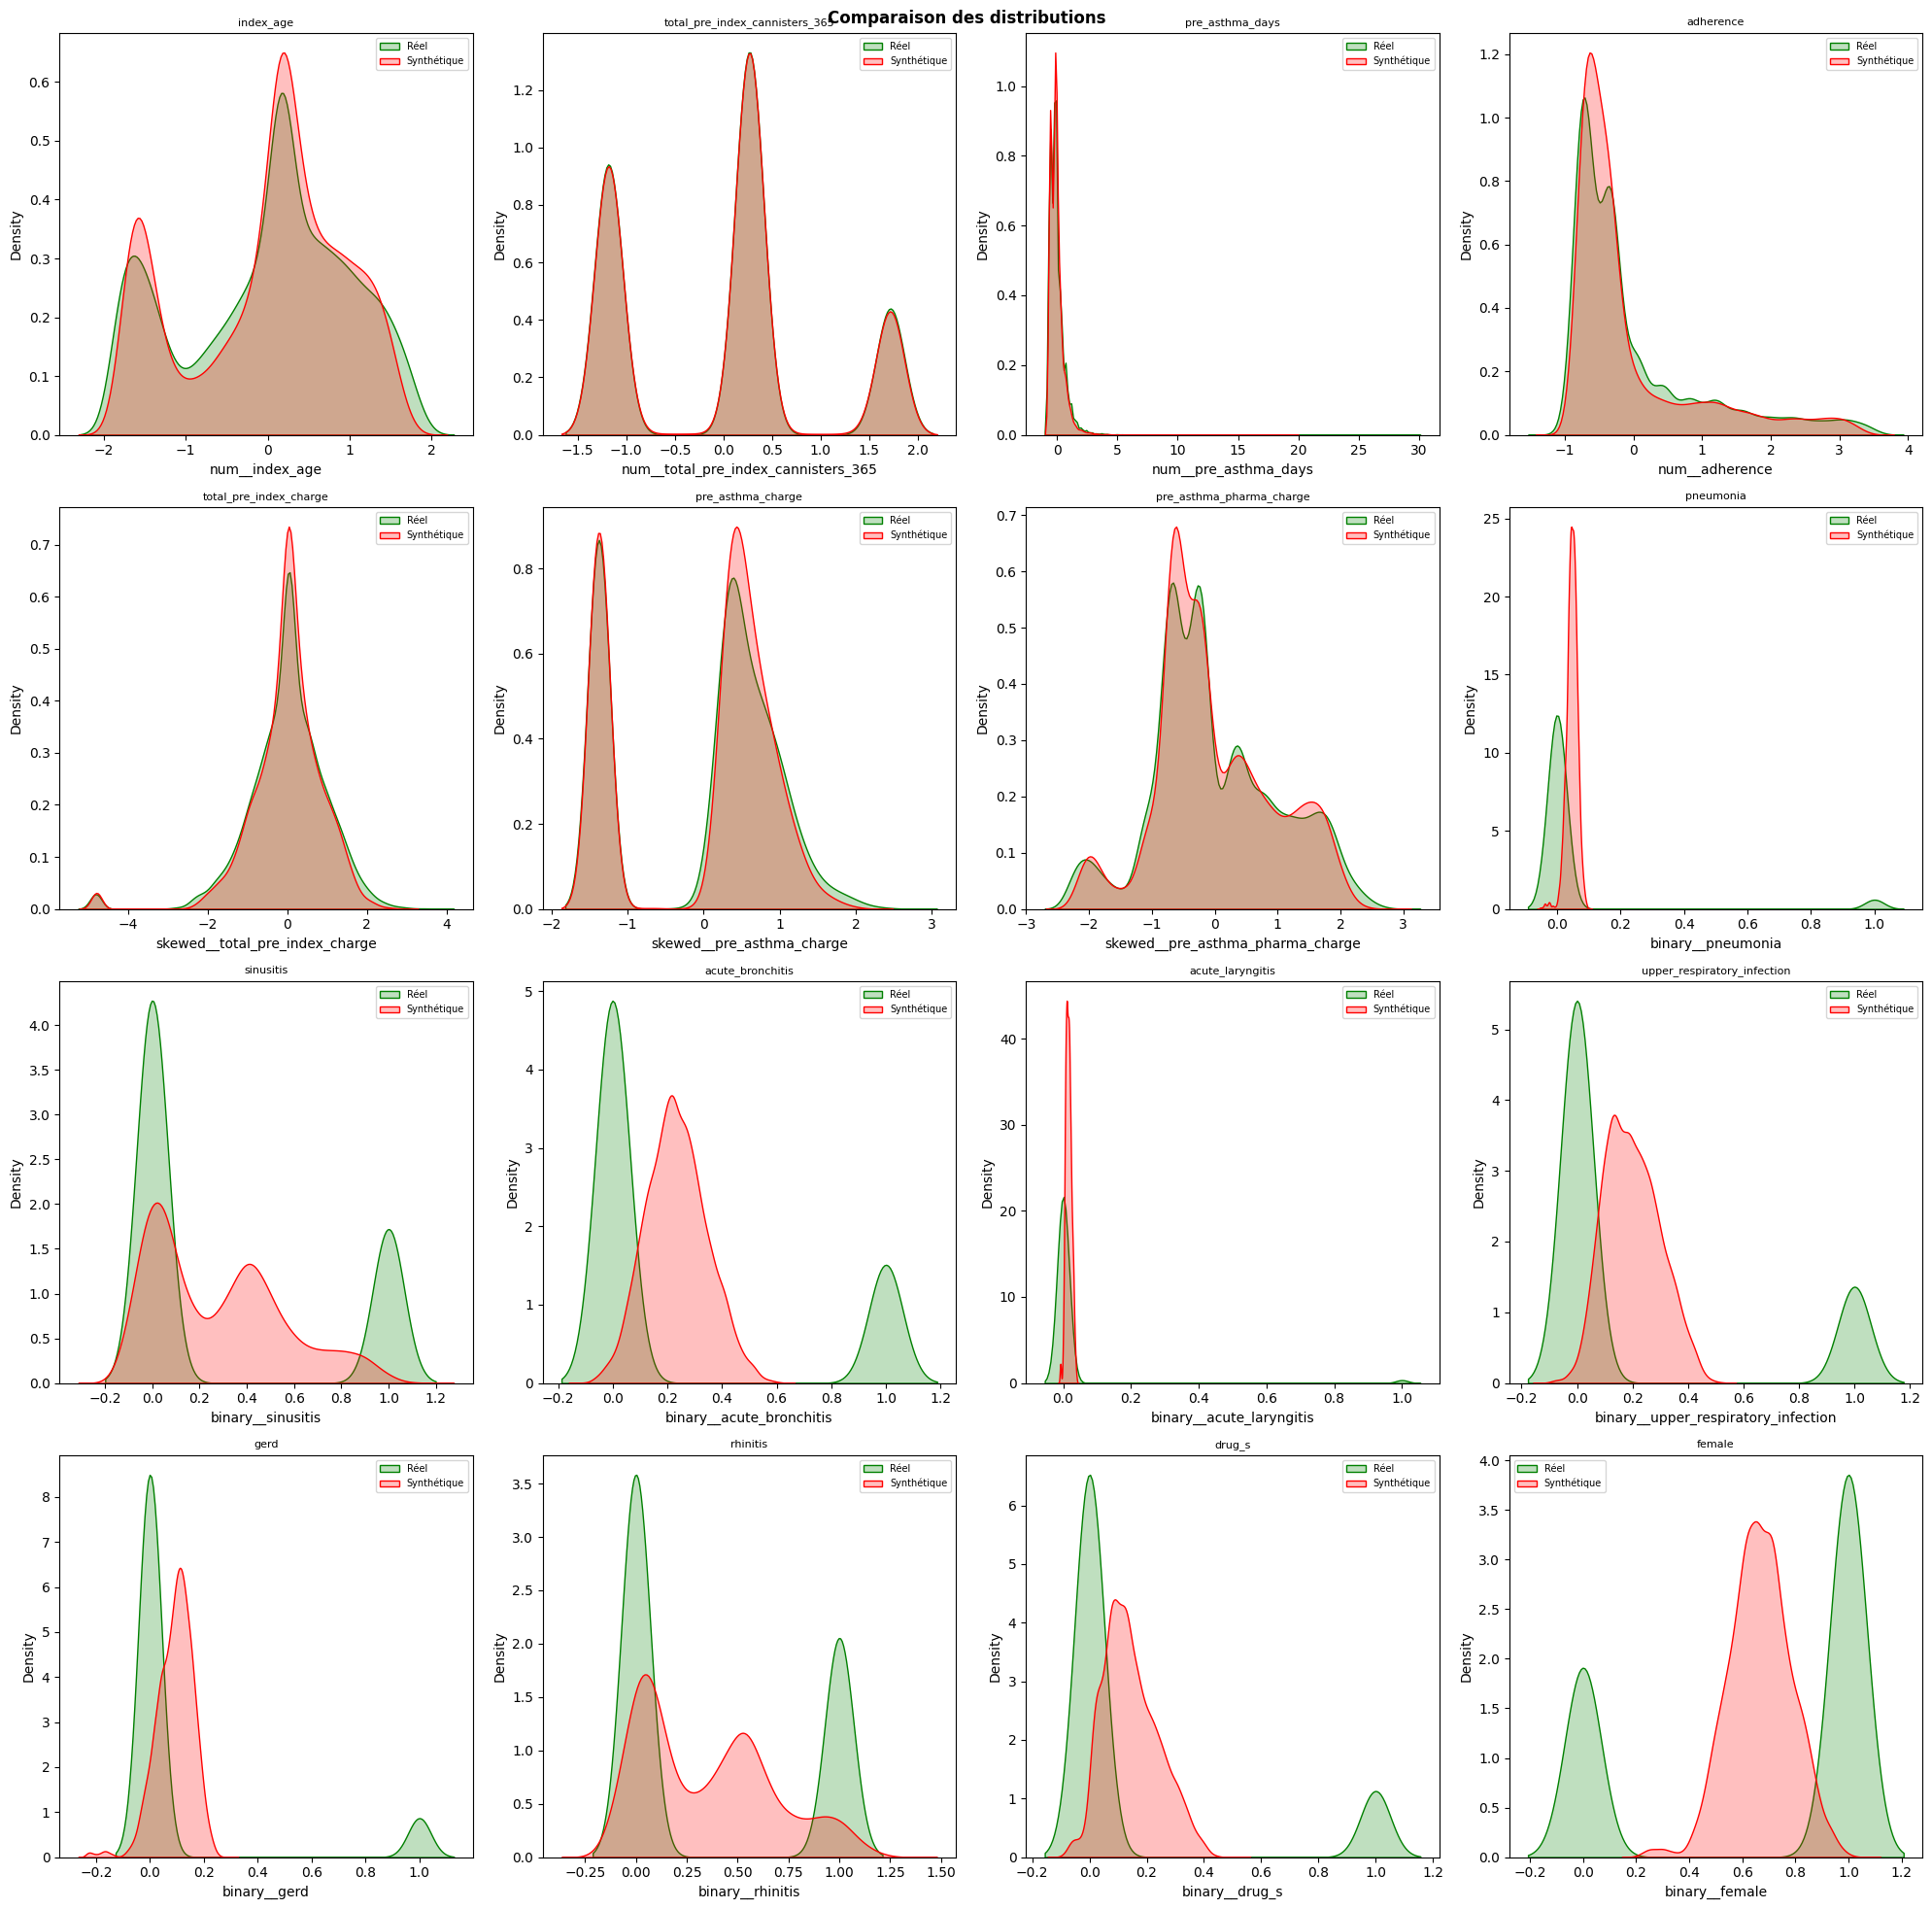

In [ ]:
# Distributions KDE de toutes les variables
n_cols = 4
n_rows = math.ceil(len(feature_names) / n_cols)

plt.figure(figsize=(20, 5 * n_rows))

for i, col in enumerate(feature_names):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.kdeplot(real_df[col],  label='Réel', fill=True, color='green')
    sns.kdeplot(df_final[col], label='Synthétique', fill=True, color='red')
    nom = col.replace('num__','').replace('skewed__','').replace('binary__','')
    plt.title(nom, fontsize=8)
    plt.legend(fontsize=7)

plt.suptitle('Comparaison des distributions', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
h

Après observation des 2 figures précédents, nous pouvons constater que les distributions des variables numériques sont globalement bien reproduites. En revanche, les variables binaires sont moins bien capturées ce qui est attendu (ce qui explique une corrélation de 22,68%), car la méthode Avatar génère des valeurs continues par interpolation entre voisins, alors que ces variables ne peuvent prendre que les valeurs 0 ou 1.

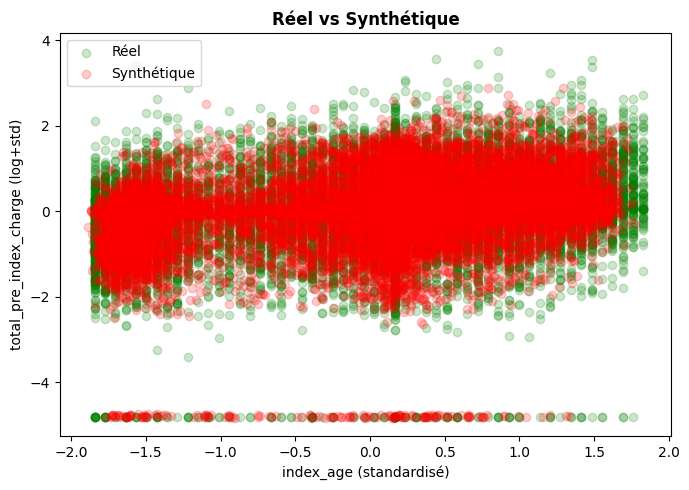

In [ ]:
# Scatter plot : données réels vs synthétiques 
# Visualise si les données synthétiques occupent le même espace que les réelles
col_x = 'num__index_age'
col_y = 'skewed__total_pre_index_charge'

plt.figure(figsize=(7, 5))
plt.scatter(real_df[col_x], real_df[col_y], alpha=0.2, color='green', label='Réel' )
plt.scatter(df_final[col_x], df_final[col_y], alpha=0.2, color='red', label='Synthétique' )
plt.xlabel('index_age (standardisé)')
plt.ylabel('total_pre_index_charge (log+std)')
plt.title('Réel vs Synthétique', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

Le nuage de points montre que les données synthétiques suivent globalement la même distribution que les données réelles, confirmant que la méthode Avatar reproduit bien la structure des données.

### Les données synthétisées conservent-t-elles les corrélations ? 

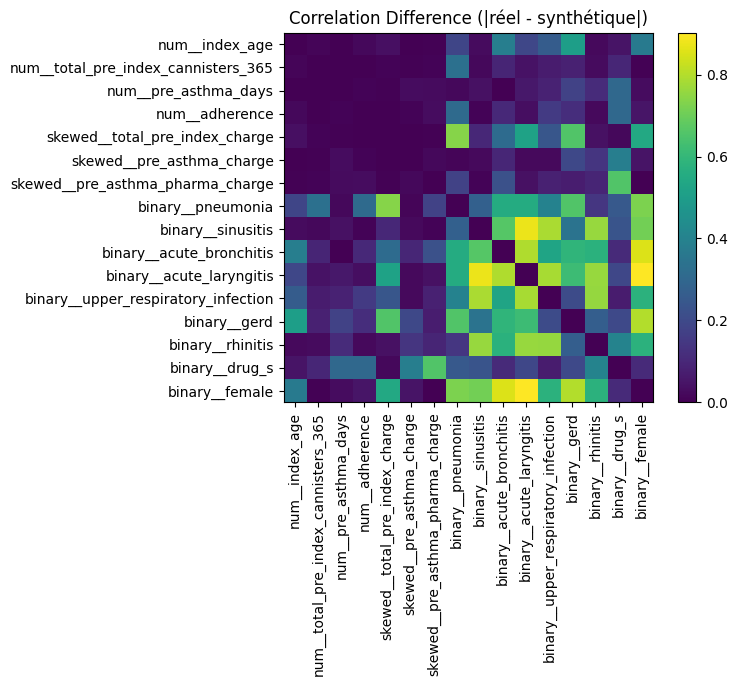

In [ ]:
# matrices de corrélation
# foncé = corrélation similaire, clair = corrélation différente
real_corr = np.corrcoef(real_df.to_numpy(),  rowvar=False)
synth_corr = np.corrcoef(df_final.to_numpy(), rowvar=False)
diff_corr = np.abs(real_corr - synth_corr)

plt.figure()
plt.imshow(diff_corr)
plt.title("Correlation Difference (|réel - synthétique|)")
plt.colorbar()
plt.xticks(range(len(real_df.columns)), real_df.columns, rotation=90)
plt.yticks(range(len(real_df.columns)), real_df.columns)
plt.show()

La matrice de différence des corrélations confirme bien que les variables numériques et financières (zone bleue foncée) ont leurs corrélations bien conservées, tandis que les variables binaires (zone jaune/verte) présentent des différences importantes. Cela illustre la limite de la méthode Avatar face aux variables binaire.

## 11. Reconstruction dans l'espace original

On applique l'inverse des transformations (StandardScaler, log1p) pour obtenir `df_final_original` avec les mêmes unités et les mêmes valeurs binaires (0/1) que les données d'origine.

- X_scaled
   - ↓
- Inverse scaling
   - ↓
- Inverse log (skewed uniquement )
   - ↓
- Reconstruction binaires (seuil par prévalence réelle → 0 ou 1)
   - ↓
- Réintégration des variables supprimées (colonnes à variance nulle restaurées avec leur valeur constante)
   - ↓
- Dataset final propre (réordonné : num + skewed + binary)

| Type      | Action                |
| --------- | --------------------- |
| Numérique | inverse scaling (+ arrondi si entier)      |
| Skewed    | inverse scaling + exp |
| Binaire   | seuil par prévalence → 0/1           |

Ce code permet de reconstruire les données originales à partir de l’espace transformé en inversant les opérations de preprocessing et en réintégrant les variables supprimées

In [ ]:
def inverse_preprocess(X_scaled, feature_names_sel, num_features, skewed_features,
                       binary_features, preprocessor, selector):
    
    # Variables entières : après inverse-scaling on arrondit (ex: 16.48 → 16)
    int_features = ['index_age', 'total_pre_index_cannisters_365',
                    'pre_asthma_days', 'previous_asthma_drugs']

    # Récupérer les 3 sous-pipelines fittés pour accéder à leurs paramètres
    num_tr    = preprocessor.named_transformers_['num']       # pipeline num
    skewed_tr = preprocessor.named_transformers_['skewed']    # pipeline skewed
    binary_tr = preprocessor.named_transformers_['binary']    # pipeline binary
    n         = X_scaled.shape[0]  # nombre de patients
    result    = {}                 # dictionnaire col_name → array résultat

    # ── PARTIE 1 : colonnes qui ont survécu au VarianceThreshold ──────────────
    for col_idx, fname in enumerate(feature_names_sel):
        x = X_scaled[:, col_idx]  # valeurs synthétiques de cette colonne

        if fname.startswith('num__'):
            # Ex: fname = 'num__index_age'
            feat = fname[5:]                          # → 'index_age'
            pos  = num_features.index(feat)           # position dans la liste
            sc   = num_tr.named_steps['scaler']
            # Inverse StandardScaler : x_original = x * std + mean
            val  = x * sc.scale_[pos] + sc.mean_[pos]
            if feat in int_features:
                val = np.round(val).clip(min=0)       # arrondi + pas de négatif
            result[feat] = val

        elif fname.startswith('skewed__'):
            # Ex: fname = 'skewed__total_pre_index_charge'
            feat = fname[8:]                          # → 'total_pre_index_charge'
            pos  = skewed_features.index(feat)
            sc   = skewed_tr.named_steps['scaler']
            # Inverse StandardScaler → on récupère la valeur log1p
            log_val = x * sc.scale_[pos] + sc.mean_[pos]
            # Inverse log1p = expm1, clip à 0 (charge ne peut pas être négative)
            result[feat] = np.clip(np.expm1(log_val), 0, None)

        elif fname.startswith('binary__'):
            # Ex: fname = 'binary__pneumonia'
            feat = fname[8:]                          # → 'pneumonia'
            # Prévalence réelle : proportion de 1 dans les vraies données
            prevalence = df_reel[feat].mean()         # ex: 0.03 = 3%
            # Seuil : top 3% des avatars (ceux avec la valeur la plus haute → 1)
            threshold  = np.percentile(x, 100 * (1 - prevalence))
            result[feat] = (x >= threshold).astype(int)  # 0 ou 1

    # ── PARTIE 2 : colonnes supprimées par VarianceThreshold ─────────────────
    # Ces colonnes avaient variance = 0 (ex: tous patients ont la même valeur)
    # On les restaure avec la valeur constante apprise lors du fit
    all_names_before = preprocessor.get_feature_names_out()
    removed_mask = ~selector.get_support()  # True = colonne supprimée
    for fname in all_names_before[removed_mask]:
        if fname.startswith('num__'):
            feat = fname[5:]
            pos  = num_features.index(feat)
            val  = num_tr.named_steps['imputer'].statistics_[pos]  # médiane fittée
            if feat in int_features:
                val = round(val)
            result[feat] = np.full(n, val)  # même valeur pour tous les patients
        elif fname.startswith('skewed__'):
            feat = fname[8:]
            pos  = skewed_features.index(feat)
            # La médiane était en espace log → on repasse en espace original
            val  = np.expm1(skewed_tr.named_steps['imputer'].statistics_[pos])
            result[feat] = np.full(n, max(0.0, val))
        elif fname.startswith('binary__'):
            feat = fname[8:]
            pos  = binary_features.index(feat)
            # Mode fitté (valeur la plus fréquente, 0 ou 1)
            val  = binary_tr.named_steps['imputer'].statistics_[pos]
            result[feat] = np.full(n, int(round(val)))

    # ── PARTIE 3 : réordonner dans l'ordre original ───────────────────────────
    # num d'abord, puis skewed, puis binary (même ordre que X_df de départ)
    ordered_cols = (
        [f for f in num_features    if f in result] +
        [f for f in skewed_features if f in result] +
        [f for f in binary_features if f in result]
    )
    return pd.DataFrame({c: result[c] for c in ordered_cols})


# Données synthétiques dans l'espace original (sans scaling, sans log, binaires en 0/1)
df_final_original = inverse_preprocess(
    X_final, feature_names,
    num_features, skewed_features, binary_features,
    preprocessor, selector
)

print("Shape :", df_final_original.shape)
print("Types :")
print(df_final_original.dtypes)


Shape : (14575, 17)
Types :
index_age                         float64
previous_asthma_drugs               int64
total_pre_index_cannisters_365    float64
pre_asthma_days                   float64
adherence                         float64
total_pre_index_charge            float64
pre_asthma_charge                 float64
pre_asthma_pharma_charge          float64
pneumonia                           int64
sinusitis                           int64
acute_bronchitis                    int64
acute_laryngitis                    int64
upper_respiratory_infection         int64
gerd                                int64
rhinitis                            int64
drug_s                              int64
female                              int64
dtype: object


In [ ]:
print("Aperçu :")
df_final_original.head()

Aperçu :


,index_age,previous_asthma_drugs,total_pre_index_cannisters_365,pre_asthma_days,adherence,total_pre_index_charge,pre_asthma_charge,pre_asthma_pharma_charge,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,drug_s,female
0,16.0,1,1.0,1.0,0.143923,2032.935437,186.810816,234.047606,0,0,0,0,0,0,0,0,0
1,37.0,1,2.0,0.0,0.168312,22820.178973,180.689251,52.073959,1,1,1,0,1,1,1,0,1
2,53.0,1,1.0,1.0,0.706577,3776.526442,381.184859,64.808602,0,0,0,0,0,0,0,0,0
3,42.0,1,2.0,0.0,0.085239,2848.961017,0.008496,51.549319,0,0,0,0,0,0,0,0,1
4,38.0,1,1.0,2.0,0.472365,938.129403,380.277799,37.901873,0,1,1,0,0,0,1,0,1


In [ ]:
# Clip index_age dans l'intervalle des valeurs réelles
# ici on avais un seul age à 11 ans dans les données synthétiques, alors que le minimum réel est à 12 ans 

age_min = int(df_reel['index_age'].min())
age_max = int(df_reel['index_age'].max())
df_final_original['index_age'] = df_final_original['index_age'].clip(lower=age_min, upper=age_max)

print(f"Age clip : [{age_min}, {age_max}]")
print(df_final_original['index_age'].value_counts().sort_index())

Age clip : [12, 65]
index_age
12.0     58
13.0    217
14.0    392
15.0    497
16.0    481
17.0    382
18.0    320
19.0    212
20.0    161
21.0    129
22.0    102
23.0     84
24.0     90
25.0     90
26.0    103
27.0     96
28.0    103
29.0    113
30.0    149
31.0    150
32.0    175
33.0    177
34.0    188
35.0    221
36.0    257
37.0    273
38.0    350
39.0    474
40.0    668
41.0    958
42.0    797
43.0    544
44.0    484
45.0    409
46.0    356
47.0    350
48.0    322
49.0    317
50.0    319
51.0    319
52.0    321
53.0    292
54.0    297
55.0    268
56.0    285
57.0    287
58.0    263
59.0    232
60.0    194
61.0    134
62.0     84
63.0     26
64.0      5
Name: count, dtype: int64


In [ ]:
df_final_original.index_age.value_counts()

index_age
41.0    958
42.0    797
40.0    668
43.0    544
15.0    497
44.0    484
16.0    481
39.0    474
45.0    409
14.0    392
17.0    382
46.0    356
38.0    350
47.0    350
48.0    322
52.0    321
18.0    320
50.0    319
51.0    319
49.0    317
54.0    297
53.0    292
57.0    287
56.0    285
37.0    273
55.0    268
58.0    263
36.0    257
59.0    232
35.0    221
13.0    217
19.0    212
60.0    194
34.0    188
33.0    177
32.0    175
20.0    161
31.0    150
30.0    149
61.0    134
21.0    129
29.0    113
26.0    103
28.0    103
22.0    102
27.0     96
24.0     90
25.0     90
62.0     84
23.0     84
12.0     58
63.0     26
64.0      5
Name: count, dtype: int64

In [ ]:
df_reel.index_age.value_counts()

index_age
12.0    380
15.0    356
13.0    352
46.0    352
47.0    348
44.0    336
45.0    334
42.0    331
14.0    330
49.0    329
43.0    322
48.0    317
50.0    315
16.0    307
40.0    306
52.0    301
17.0    298
51.0    298
53.0    296
41.0    293
37.0    284
36.0    283
38.0    282
39.0    278
18.0    275
54.0    269
55.0    260
35.0    258
57.0    253
59.0    249
58.0    237
34.0    236
56.0    232
33.0    228
19.0    226
60.0    200
31.0    191
32.0    190
20.0    187
61.0    184
30.0    174
62.0    165
29.0    163
28.0    157
63.0    147
21.0    143
26.0    132
27.0    127
64.0    116
25.0    105
22.0    102
24.0     94
23.0     89
65.0     68
Name: count, dtype: int64

In [ ]:
df_final_original.index_age.value_counts()

index_age
41.0    958
42.0    797
40.0    668
43.0    544
15.0    497
44.0    484
16.0    481
39.0    474
45.0    409
14.0    392
17.0    382
46.0    356
38.0    350
47.0    350
48.0    322
52.0    321
18.0    320
50.0    319
51.0    319
49.0    317
54.0    297
53.0    292
57.0    287
56.0    285
37.0    273
55.0    268
58.0    263
36.0    257
59.0    232
35.0    221
13.0    217
19.0    212
60.0    194
34.0    188
33.0    177
32.0    175
20.0    161
31.0    150
30.0    149
61.0    134
21.0    129
29.0    113
26.0    103
28.0    103
22.0    102
27.0     96
24.0     90
25.0     90
62.0     84
23.0     84
12.0     58
63.0     26
64.0      5
Name: count, dtype: int64

In [ ]:
df_reel.total_pre_index_charge.value_counts()

total_pre_index_charge
1.000000        153
42.394472         3
372.967765        2
118.465760        2
72.718296         2
               ... 
39076.906969      1
4031.590780       1
33667.611169      1
961.265928        1
2101.533966       1
Name: count, Length: 12940, dtype: int64

In [ ]:
df_final_original.total_pre_index_charge.value_counts()

total_pre_index_charge
2032.935437     1
22820.178973    1
3776.526442     1
2848.961017     1
938.129403      1
               ..
5833.793717     1
4024.041913     1
76979.937772    1
794.607220      1
3227.278729     1
Name: count, Length: 14575, dtype: int64

Binaire verification 

In [ ]:
df_final_original.pneumonia.unique()

array([0, 1])

In [ ]:
df_final_original.sinusitis.unique()

array([0, 1])

In [ ]:
df_final_original.acute_bronchitis.unique()

array([0, 1])

In [ ]:
df_final_original.acute_laryngitis.unique()

array([0, 1])

In [ ]:
df_final_original.upper_respiratory_infection.unique()

array([0, 1])

In [ ]:
df_final_original.gerd.unique()

array([0, 1])

In [ ]:
df_final_original.rhinitis.unique()

array([0, 1])

In [ ]:
df_final_original.drug_s.unique()

array([0, 1])

In [ ]:
df_final_original.female.unique()

array([0, 1])

In [ ]:
# Export du dataset synthétique dans le output
output_path = "../../outputs/Groupe5_Abdo_Talha_Flora_projet3.csv"
df_final_original.to_csv(output_path, index=False)
print(f"Fichier sauvegardé : {output_path}")
print(f"Shape : {df_final_original.shape}")
df_final_original.head()


Fichier sauvegardé : ../../outputs/Groupe5_Abdo_Talha_Flora_projet3.csv
Shape : (14575, 17)


,index_age,previous_asthma_drugs,total_pre_index_cannisters_365,pre_asthma_days,adherence,total_pre_index_charge,pre_asthma_charge,pre_asthma_pharma_charge,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,drug_s,female
0,16.0,1,1.0,1.0,0.143923,2032.935437,186.810816,234.047606,0,0,0,0,0,0,0,0,0
1,37.0,1,2.0,0.0,0.168312,22820.178973,180.689251,52.073959,1,1,1,0,1,1,1,0,1
2,53.0,1,1.0,1.0,0.706577,3776.526442,381.184859,64.808602,0,0,0,0,0,0,0,0,0
3,42.0,1,2.0,0.0,0.085239,2848.961017,0.008496,51.549319,0,0,0,0,0,0,0,0,1
4,38.0,1,1.0,2.0,0.472365,938.129403,380.277799,37.901873,0,1,1,0,0,0,1,0,1


: 

# Conclusion

Le modèle reproduit bien les distributions (écart Wasserstein assez faible) ainsi que les relations entre variables (corrélation préservée). Les données synthétiques ne contiennent aucun doublon des données réelles, et la distance minimale moyenne confirme une bonne protection contre le risque de ré-identification.

La grille de recherche a permis d'identifier le meilleur compromis entre fidélité statistique (utile pour les modèles ML des Projets 1 et 2) et confidentialité (protection des patients).

Néanmoins la méthode Avatar présente une petite limite : étant basée sur une projection PCA et une interpolation continue entre voisins, elle reproduit moins fidèlement les variables binaires dont les corrélations sont partiellement dégradées dans les données synthétiques.